# Фьючерсы MOEX на сырьё: данные AlgoPack и исследование стратегии «MA + наклон»

**Презентация проделанной работы** · данные по 13.10.2026 · ветка `ccr-cf486678-oggs1n`

| Часть | О чём |
|---|---|
| 1 | Что сделано и главный результат |
| 2 | Данные MOEX AlgoPack: 8 сырьевых фьючерсов |
| 3 | Склейка контрактов и исправление метрик |
| 4 | Исследование: стратегия, пространство поиска, защита от подгонки |
| 5 | Результаты: 11 слайдов |
| 6 | Итог, рекомендации, где что лежит |

Ноутбук уже выполнен и читается на GitHub без запуска. Подробный отчёт —
[`research/ma_cross_slope_5m/README.md`](../research/ma_cross_slope_5m/README.md), интерактивный разбор любой
конфигурации — [`06_ma_slope_research.ipynb`](06_ma_slope_research.ipynb).

In [1]:
# Подготовка: все цифры ниже читаются из файлов репозитория
import warnings

warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Markdown, display

from src.ma_slope import presentation as pres
from src.ma_slope.analysis import holm

show, table, NAMES = pres.show, pres.table, pres.NAMES
INF = ["ng", "br", "gold", "silv", "plt", "pld", "copper"]  # WTI: 2 181 бар, только справочно
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
summary = pres.summary()

## 1. Что сделано

1. **Данные.** Загружены котировки 8 сырьевых фьючерсов MOEX **только из AlgoPack**: NG, Brent (BR), CL (WTI),
   GC (GOLD), SI (SILV), HG (COPPER), PL (PLT), PA (PLD). Минутные, 5-минутные и часовые свечи за всю доступную
   историю, с 2011 года по 13.10.2026.
2. **Склейка и метрики.** Контракты склеены **пропорционально**, по вашему решению. Загрузчик отдаёт ряды прямо
   в VectorBT. Исправлен годовой пересчёт метрик: Sharpe на часовых данных был завышен в 1,5–1,9 раза.
3. **Исследование.** Проверена стратегия «цена пересекает быструю MA, направление разрешает наклон медленной MA»
   на 5-минутках: 6 типов средних, все 36 сочетаний, Fast 2–99 × Slow 5–250, два метода наклона, две модели выхода.
   Это **около 9 млн конфигураций на инструмент** и около 64 млн бэктестов всего.
4. **Проверка.** IS/OOS, walk-forward, польза отбора, PBO, Monte Carlo, поправки Холма и Benjamini–Hochberg,
   межрыночная проверка. Ядро симуляции сверено с VectorBT сделка в сделку.

> **Главный результат.** Устойчивого преимущества у конкретных параметров **нет**: после поправок на
> множественное тестирование ни одна конфигурация не подтверждается. Зато есть воспроизводимые закономерности
> правил: выход по смене наклона, горизонт наклона 40–80 баров. Ежегодный переотбор параметров даёт плюс на всех
> 6 рынках с длинной историей. Но средняя сделка всего 0,5–1,8 тика, поэтому без учёта издержек торговать это
> нельзя.

In [2]:
ov = pres.data_overview()
kpi = {
    "инструментов": len(ov),
    "минутных свечей": f"{ov['свечей 1m'].sum():,}".replace(",", " "),
    "5-минутных баров": f"{ov['баров 5m'].sum():,}".replace(",", " "),
    "контрактов склеено": int(ov["контрактов"].sum()),
    "переходов между контрактами": int(ov["переходов"].sum()),
    "конфигураций проверено": f"{sum(summary['trials_per_instrument'].values()):,}".replace(",", " "),
}
pd.DataFrame(kpi, index=["проект в цифрах"]).T

,проект в цифрах
инструментов,8
минутных свечей,10 726 863
5-минутных баров,2 702 766
контрактов склеено,510
переходов между контрактами,502
конфигураций проверено,63 762 102


## 2. Данные MOEX AlgoPack

* **Источник** — только AlgoPack (`apim.moex.com`) по вашему токену. Токен в репозиторий не попал. Сертификат
  сервера подписан российским корневым центром, поэтому подключён официальный Russian Trusted Root CA. Проверка
  TLS не отключалась.
* **Список контрактов.** Справочник серий MOEX неполный, поэтому недостающие месяцы найдены перебором кодов
  (`BRQ3`, `BRQ3_2013`…). Всего 510 контрактов.
* **Непрерывный ряд по ближайшей экспирации.** Контракт держится до последнего дня обращения. Следующий берётся
  со следующего дня, а если старый перестал торговаться раньше — сразу после его последней свечи. Так закрыт
  разрыв NG в 2020 году.
* **Таймфреймы.** 1m — из API, 5m — собраны из 1m, 60m — исходные часовые свечи. Хранение: CSV по годам в
  `data/raw/moex_algopack/<тикер>/<таймфрейм>/`.

In [3]:
pres.data_overview()

,мировой тикер,начало,конец,свечей 1m,баров 5m,контрактов,переходов,"макс. разрыв на ролле, %",граница IS/OOS,USD за пункт,тик
инструмент,,,,,,,,,,,
NG,NG,2020-02-03,2026-10-13,1274560,282539,81,80,47.8,2025-02-07,100,0.001
BR (Brent),Brent,2011-12-19,2026-10-13,2837316,607705,177,176,13.5,2022-11-03,10,0.01
WTI (CL),CL,2026-07-14,2026-10-13,2704,2181,3,2,6.8,2026-09-28,10,0.01
GOLD (GC),GC,2011-12-19,2026-10-13,2780928,614498,60,59,4.3,2022-10-24,1,0.1
SILV (SI),SI,2011-12-19,2026-10-13,2103771,564537,60,59,8.6,2023-02-27,10,0.01
PLT (PL),PL,2011-12-19,2026-10-13,893872,331877,60,59,15.5,2024-07-17,1,0.1
PLD (PA),PA,2011-12-19,2026-10-13,666550,237104,60,59,8.2,2025-04-25,1,0.01
COPPER (HG),HG,2024-10-08,2026-10-13,167162,62325,9,8,4.4,2026-05-29,0.01,1


**Оговорки.** CL (WTI) торгуется на MOEX только с июля 2026 года, это 2 181 пятиминутный бар: в выводах он не
участвует. У HG (COPPER) два года истории, поэтому для него нет walk-forward и PBO. У NG крупнейший разрыв
(48 %) — переход с январского на февральский контракт 2026 года, когда январский контракт резко вырос перед
экспирацией.

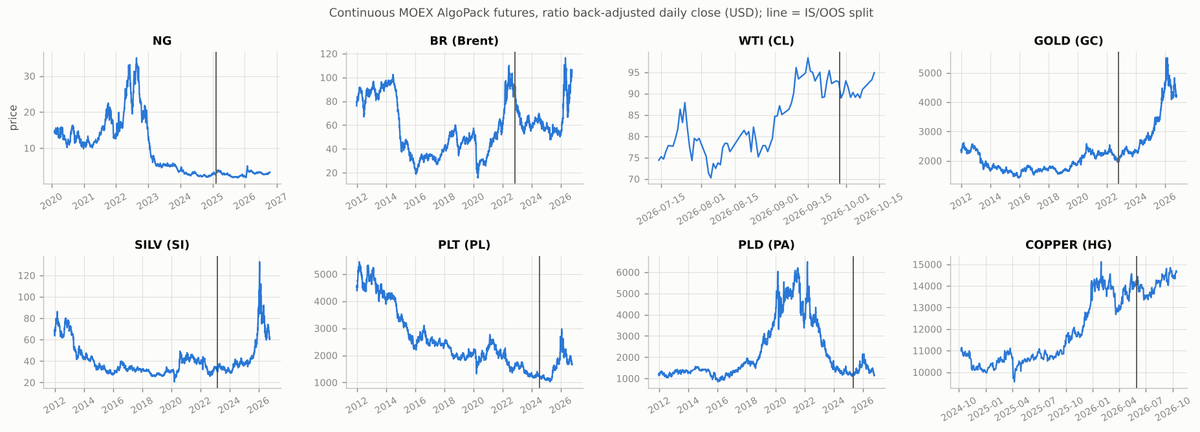

In [4]:
show("overview_prices.png")

## 3. Склейка контрактов: пропорциональная, как вы решили

На каждом переходе в одну и ту же минуту — последнюю свечу старого контракта — берутся цены старого и нового
контракта. Вся история до перехода умножается на их отношение.

* Скачок на ролле исчезает. Значит, нет ложных пересечений средних и ложных изменений наклона.
* Процентные движения ряда — это движения контракта, который реально держали бы.
* Последний контракт сохраняет настоящие цены.
* Коэффициенты всех 502 переходов лежат в `rolls.csv`. Загрузчик `load_data("moex_algopack", ...)` применяет их
  по умолчанию, а `adjust=None` отдаёт сырые цены.

Денежный PnL в исследовании считается иначе: по изменению **сырой** цены удерживаемого контракта × размер
контракта. Позиция переходит в новый контракт по цене перекрытия, без скачка.

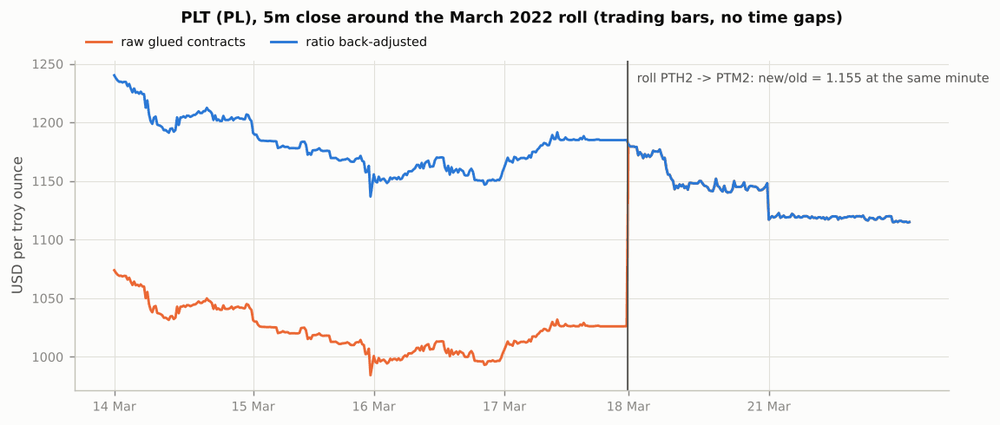

In [5]:
show("roll_example_plt.png", width=1000)

## 3. Исправление метрик: годовой пересчёт

VectorBT переводит метрики в годовые через частоту бара. Для часовых свечей это давало 8 760 баров в год
(круглосуточно), хотя MOEX торгует примерно 2 500–4 200 часов в год. Sharpe из-за этого завышался в
√(8760 / факт) раз.

**Исправление:** `BacktestConfig(freq="auto")` берёт среднее календарное время на бар из самих данных. Годовые
Sharpe, Sortino, CAGR и длительности теперь считаются по фактически торгуемым барам. Исправление действует во всех
модулях репозитория: движке бэктестов, исследованиях и управлении позицией.

In [6]:
pres.annualization_check()

,часовых свечей в год (факт),по часам 24/7,"завышение Sharpe при 24/7, раз"
инструмент,,,
NG,3883,8760,1.50
BR (Brent),3627,8760,1.55
WTI (CL),3433,8760,1.60
GOLD (GC),3657,8760,1.55
SILV (SI),3653,8760,1.55
PLT (PL),3105,8760,1.68
PLD (PA),2540,8760,1.86
COPPER (HG),4182,8760,1.45


## 4. Стратегия: правила

* **Вход.** Close пересекает быструю MA (Fast) по двум закрытым свечам, сделка открывается по Open следующей
  свечи. Long — при пересечении вверх, если наклон медленной MA (Slow) вверх или нейтральный. Short — при
  пересечении вниз, если наклон вниз или нейтральный.
* **Наклон Slow MA за k баров.** Метод A: `(MA[t] − MA[t−k]) / MA[t−k] · 100 %`. Метод B: `(MA[t] − MA[t−k]) / ATR`.
  При |наклон| ≤ ε наклон нейтральный.
* **Выход A (`reverse_cross`)** — обратное пересечение Fast MA. **Выход B (`slope_flip`)** — наклон Slow MA стал
  противоположным.
* Одна позиция, 1 контракт, без комиссий и проскальзывания (по ТЗ), без разворота на свече выхода.

Ниже — правила на реальных свечах: лучшая конфигурация NG, три дня октября 2026 года. Окно выбрано автоматически:
последние три будних дня, где есть long и short, прибыль и убыток.

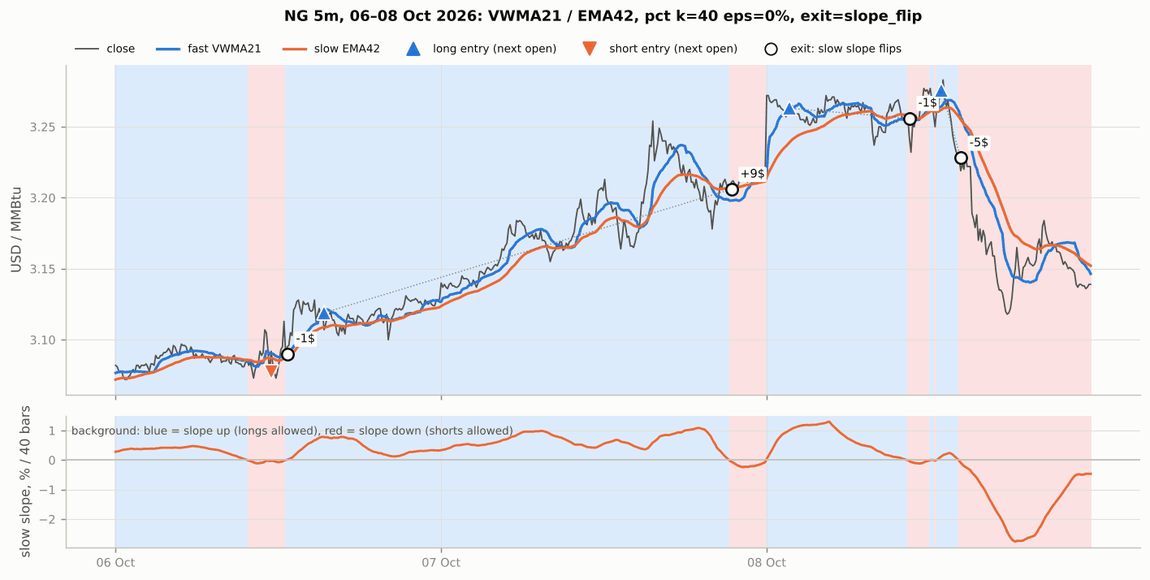

In [7]:
show("strategy_example_ng.png", width=1150)

## 4. Пространство поиска: без произвольных сокращений

| Измерение | Значения | Число |
|---|---|---:|
| Типы средних | SMA, EMA, WMA, SSMA (Wilder), VWMA, TMA | 6 |
| Пары «быстрая × медленная» | все сочетания, включая одинаковые типы | 36 |
| Период Fast | 2–99 | 98 |
| Период Slow | 5–250, включая Fast ≥ Slow как отдельную категорию | 246 |
| Метод наклона | A — в %, B — в ATR | 2 |
| Модель выхода | обратное пересечение / смена наклона | 2 |
| Настройки наклона | k ∈ {1…160}, ε, ATR ∈ {14, 100} | 128 |

Полное произведение — 222 млн конфигураций на инструмент, около 4 суток счёта. Поэтому оптимизация поэтапная, и
это изменение плана задокументировано в отчёте:

1. **Этап 1** — полная сетка 3,47 млн конфигураций при наклоне, заданном заранее (k = 10). Это контроль.
2. **Этап 2** — 128 настроек наклона на решётке периодов. Когда оптимумы упёрлись в k = 40, сетка была расширена
   до k = 160.
3. **Этап 3** — снова полная сетка с наклоном, выбранным только по IS. Это основной результат.

Итого 8 979 840 конфигураций на инструмент с длинной историей, около 6 часов счёта на 4 ядрах (numba).

## 4. Как защищались от подгонки

* **IS / OOS.** Первые 70 % баров — обучение, последние 30 % — независимая проверка. Сделка относится к периоду,
  в котором она закрыта.
* **Отбор не по максимальной прибыли**, а по **плато**: средний IS t-stat соседей (Fast ±2, Slow ±5), не меньше
  100 сделок.
* **Множественное тестирование:** поправка Холма по финалистам, Benjamini–Hochberg по лучшим конфигурациям
  групп, сравнение с ожидаемым максимумом t среди 9 млн нулевых тестов.
* **Walk-forward:** 3 года обучения → следующий год, отбор среди всех 3,47 млн конфигураций, 68 тестовых лет.
* **Польза отбора:** перцентиль выбранной конфигурации среди всех конфигураций тестового периода (0,5 — случайный
  выбор).
* **PBO (CSCV)** — вероятность переобучения отбора. **Monte Carlo** — 10 000 бутстрэпов сделок.
* **Межрыночная проверка:** одни правила на всех рынках, перенос лучших параметров с рынка на рынок.
* **Корректность:** ядро симуляции сверено с независимым побарным симулятором и с `vectorbt.Portfolio.from_signals`.
  Совпадают все сделки, расхождение PnL — около 10⁻¹³ USD. На модуль 41 тест.

## 5.1 Результат определяет режим рынка, а не параметры

Одни и те же правила зарабатывают или теряют почти всей сеткой сразу. На золоте и серебре с выходом по обратному
пересечению в IS (2012–2022) убыточны 98–100 % конфигураций, а в OOS (2022–2026) прибыльны 67–78 %. У PLT и PLD —
наоборот. Медианный OOS t разных рынков различается на 2,9, а 36 сочетаний типов средних внутри рынка — лишь на
0,7–1,1.

In [8]:
s = table("grid_summary.csv")
s = s[(s["stage"] == "stage3") & s["ticker"].isin(INF)]
w = s.assign(**{c: s[c] * s["configs"] for c in ("is_share_pos", "oos_share_pos", "is_t_median", "oos_t_median")})
g = w.groupby(["ticker", "model"])[["configs", "is_share_pos", "oos_share_pos", "is_t_median", "oos_t_median"]].sum()
g = g.iloc[:, 1:].div(g["configs"], axis=0)
g.columns = ["IS: доля t>0", "OOS: доля t>0", "IS: медиана t", "OOS: медиана t"]
g.rename(index=NAMES).loc[[NAMES[t] for t in INF]].rename_axis(["инструмент", "выход"])

IS: доля t>0  OOS: доля t>0  IS: медиана t  OOS: медиана t
инструмент  выход                                                                    
NG          reverse_cross          0.78           0.84           1.06            0.87
            slope_flip             0.97           0.79           1.59            0.57
BR (Brent)  reverse_cross          0.82           0.27           1.10           -0.40
            slope_flip             0.99           0.88           2.12            0.77
GOLD (GC)   reverse_cross          0.02           0.78          -1.53            0.74
            slope_flip             0.79           1.00           0.47            1.96
SILV (SI)   reverse_cross          0.00           0.67          -3.36            0.31
            slope_flip             0.47           0.97          -0.02            1.34
PLT (PL)    reverse_cross          1.00           0.09           1.93           -0.75
            slope_flip             1.00           0.51           2.25            0.03
PLD (PA)    reverse_cross          0.95           0.37           1.34           -0.28
            slope_flip             0.98           0.50           2.00           -0.03
COPPER (HG) reverse_cross          0.00           0.01          -2.85           -1.56
            slope_flip             0.19           0.58          -0.77            0.15

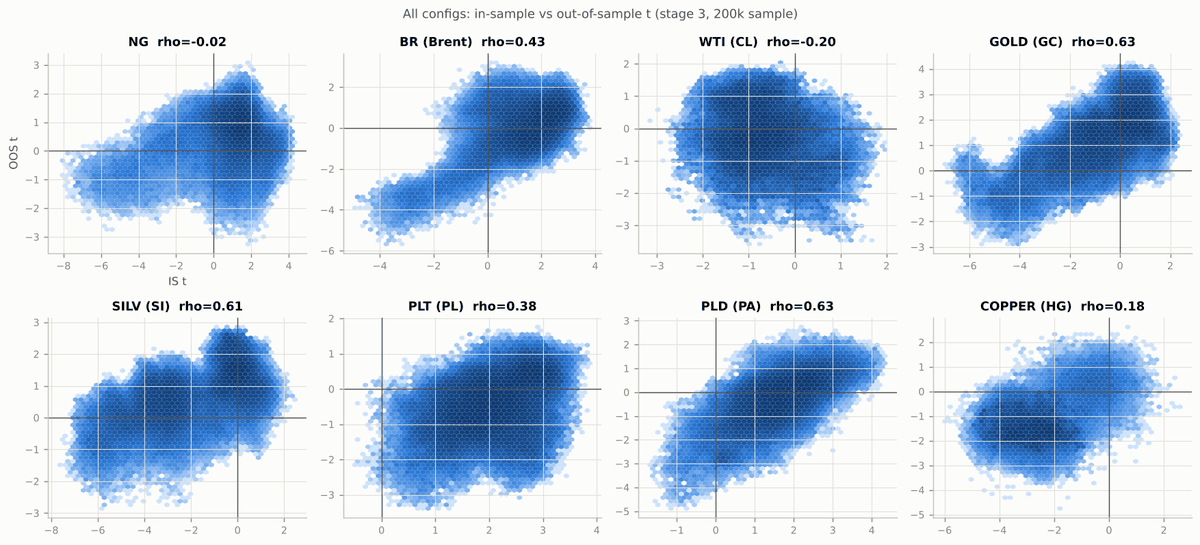

In [9]:
show("is_vs_oos.png")

## 5.2 Выход по смене наклона лучше выхода по обратному пересечению

Медианный t-stat выхода B выше на IS на всех 7 рабочих рынках и на OOS на 6 из 7 (кроме NG). Все финалисты
используют выход B. Быстрые входы-выходы на 5-минутках систематически проигрывают там, где цена возвращается
к среднему: у COPPER выход A убыточен у 100 % конфигураций на IS.

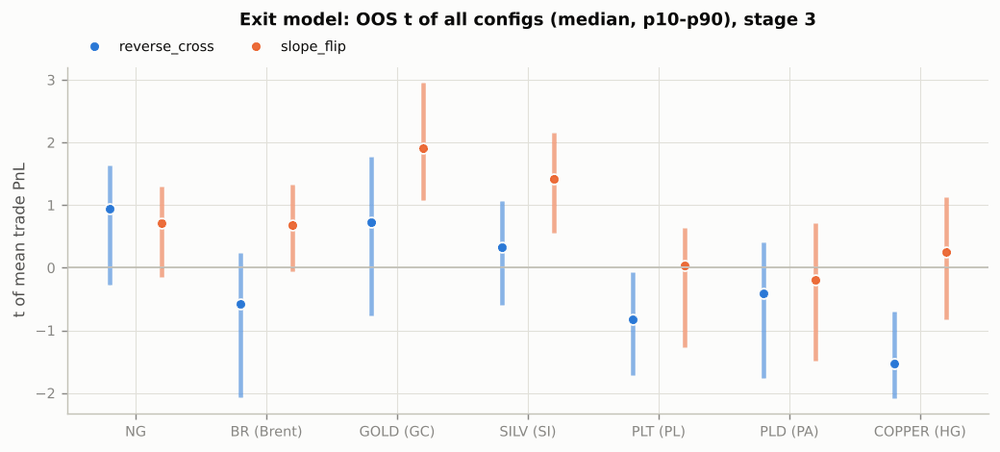

In [10]:
show("exit_models_oos.png", width=1000)

## 5.3 Главный параметр фильтра — горизонт наклона k

Медианный IS t по всем рынкам растёт с −1,08 при k = 1 до +0,11 при k = 80 баров (≈ 7 часов) и снова падает при
k = 160. Порог нейтральной зоны ε почти ни на что не влияет. Методы A (в %) и B (в ATR) после подбора
равноценны.

In [11]:
sw = table("slope_sweep.csv")
sw = sw[sw["ticker"].isin(INF)]
display(Markdown("**Медианный IS t по всем рынкам и решётке периодов в зависимости от k**"))
sw.groupby("k")["is_median_t"].mean().to_frame("IS t, медиана").T

**Медианный IS t по всем рынкам и решётке периодов в зависимости от k**

k,1,3,5,10,20,40,80,160
"IS t, медиана",-1.08,-0.80,-0.66,-0.45,-0.23,-0.02,0.11,-0.35


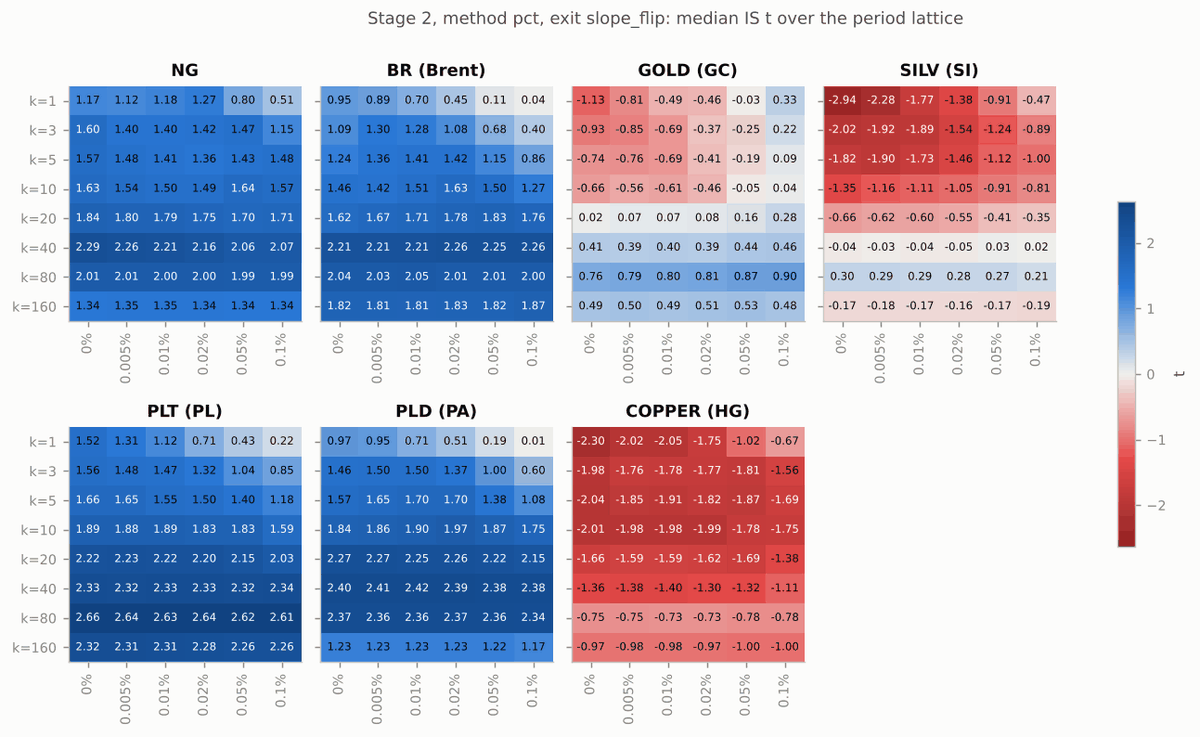

In [12]:
show("slope_sweep_pct_slope_flip.png")

## 5.4 Типы средних — эффект второго порядка

Лучшие сочетания — медленная EMA с быстрой TMA, VWMA или SMA: средний медианный OOS t 0,34–0,40. Худшие — быстрая
SSMA с медленной SMA или TMA: около −0,1. Медленные EMA, SSMA и WMA немного лучше медленных SMA, TMA и VWMA.
Но разница между типами меньше, чем между рынками и периодами.

Категория **Fast ≥ Slow** («перевёрнутые» периоды) не хуже стандартной: фильтр наклона и выход B работают при
любом соотношении периодов.

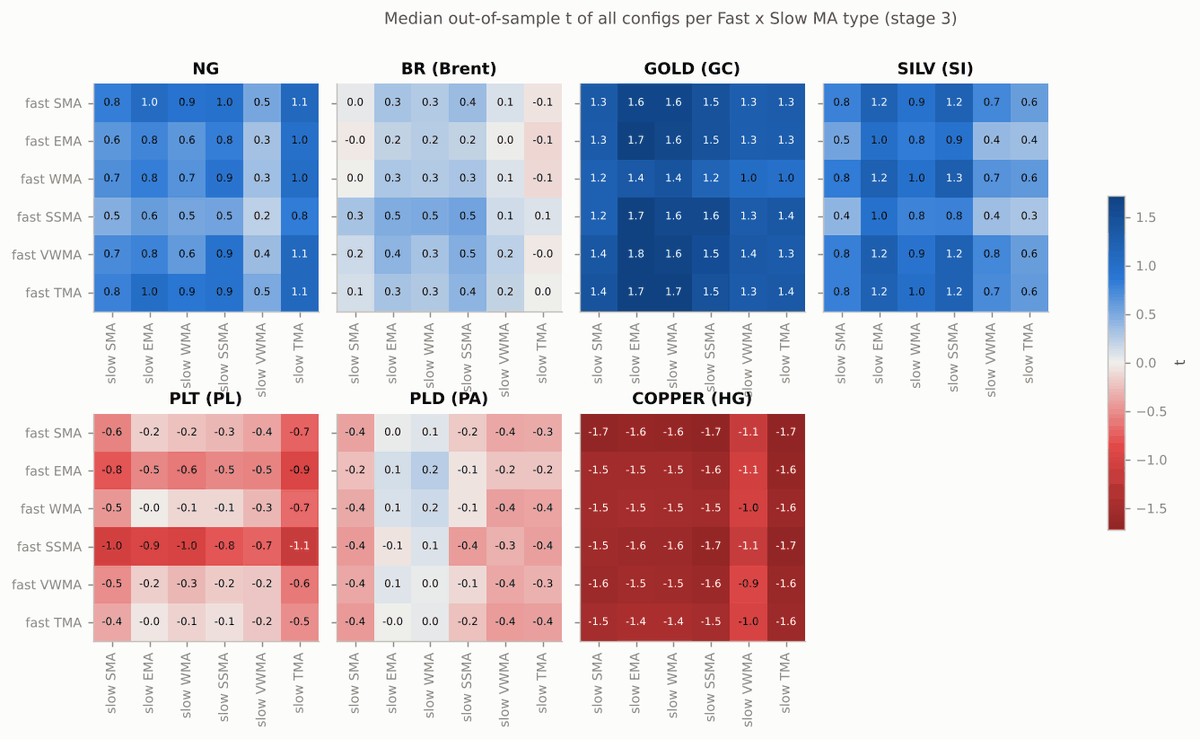

In [13]:
show("type_pairs_oos_median_t.png")

## 5.5 Лучшие конфигурации по инструментам

Для каждого инструмента выбрана лучшая конфигурация по плато IS t, затем она проверена на OOS. Sharpe и Sortino
посчитаны через VectorBT по дневному PnL одного контракта.

In [14]:
fz = table("finalists.csv")
f = fz[(fz["stage"] == "stage3") & (fz["tag"] == "overall")].set_index("ticker").loc[INF]
pd.DataFrame({
    "Fast": f["fast_type"] + f["fast_period"].astype(str), "Slow": f["slow_type"] + f["slow_period"].astype(str),
    "наклон": f["slope"], "выход": f["model"], "IS сделок": f["is_trades"].astype(int), "IS t": f["is_t"],
    "OOS сделок": f["oos_trades"].astype(int), "OOS PnL, $": f["oos_pnl"].round().astype(int),
    "OOS PF": f["oos_profit_factor"], "OOS t": f["oos_t"], "p (Холм)": f["oos_p_holm"], "Sharpe IS": f["is_sharpe"],
    "Sharpe OOS": f["oos_sharpe"],
}).rename(index=NAMES).rename_axis("инструмент")

,Fast,Slow,наклон,выход,IS сделок,IS t,OOS сделок,"OOS PnL, $",OOS PF,OOS t,p (Холм),Sharpe IS,Sharpe OOS
инструмент,,,,,,,,,,,,,
NG,VWMA21,EMA42,pct k=40 eps=0%,slope_flip,2033,4.08,911,156,1.07,0.53,0.93,1.95,0.39
BR (Brent),WMA91,VWMA200,atr k=40 eps=0.25 atr=100,slope_flip,1694,3.82,785,43,1.01,0.09,0.93,1.13,0.02
GOLD (GC),SSMA61,VWMA206,pct k=80 eps=0.1%,slope_flip,1132,2.30,480,1355,1.20,1.08,0.84,0.65,0.55
SILV (SI),VWMA98,TMA25,pct k=80 eps=0%,slope_flip,3360,2.14,1389,256,1.12,0.73,0.93,0.65,0.31
PLT (PL),TMA20,VWMA112,pct k=80 eps=0%,slope_flip,1231,3.81,588,965,1.16,0.95,0.86,1.19,0.57
PLD (PA),WMA73,WMA50,pct k=40 eps=0.01%,slope_flip,1699,4.29,690,943,1.22,1.38,0.58,1.20,1.17
COPPER (HG),VWMA16,WMA16,pct k=1 eps=0.1%,slope_flip,143,1.39,16,5,1.31,0.40,0.93,1.18,0.50


Профиль классический трендовый: около 35 % прибыльных сделок, средняя прибыль примерно вдвое больше среднего
убытка. На OOS все 7 финалистов в плюсе, но OOS t всего 0,09–1,38. После поправки Холма значимых нет: минимальное
p = 0,58. Sharpe на OOS ниже, чем на IS, у всех; почти не изменился только у PLD (1,20 → 1,17).

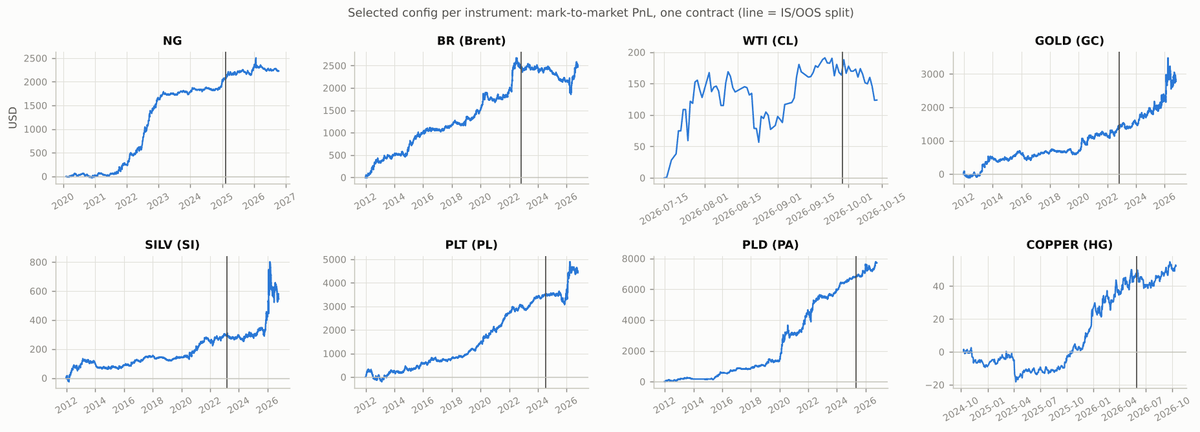

In [15]:
show("equity_finalists.png")

## 5.6 Множественное тестирование: выдающихся результатов нет

При 9 млн проверок на инструмент даже на случайных данных лучший t был бы около 5,3. Лучшие IS t-плато
финалистов не выше 4,2, то есть ниже этого порога. Поэтому решения принимались только по OOS и walk-forward, с поправками.

In [16]:
rk = table("ranking_group_bests.csv")
rk3 = rk[(rk["stage"] == "stage3") & rk["ticker"].isin(INF)]
pd.DataFrame({"значение": {
    "ожидаемый максимум t среди 9 млн нулевых тестов": f"{summary['expected_max_t_null']['ng']:.2f}",
    "лучшее IS t-плато финалистов": f"{f['is_plateau_t'].max():.2f}",
    "минимальное p финалистов после Холма": f"{f['oos_p_holm'].min():.2f}",
    "лучших конфигураций групп (тип × тип × метод × выход)": str(len(rk3)),
    "из них с OOS t > 0": str(int((rk3["oos_t"] > 0).sum())),
    "из них значимы после Benjamini–Hochberg (q < 0,05)": str(int((rk3["oos_q_bh"] < 0.05).sum())),
    "минимальный q": f"{rk3['oos_q_bh'].min():.3f}",
}})

,значение
ожидаемый максимум t среди 9 млн нулевых тестов,5.29
лучшее IS t-плато финалистов,4.22
минимальное p финалистов после Холма,0.58
лучших конфигураций групп (тип × тип × метод × выход),990
из них с OOS t > 0,646
"из них значимы после Benjamini–Hochberg (q < 0,05)",0
минимальный q,0.082


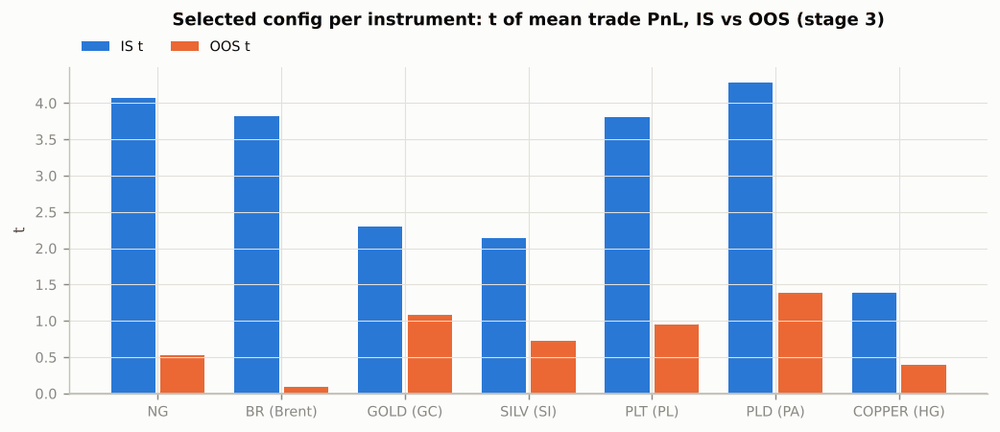

In [17]:
show("finalists_is_vs_oos.png", width=1000)

## 5.7 Карта устойчивости: плато, а не пик

Карта Fast × Slow для слоя лучшей конфигурации PLD: IS t, сглаженное плато, доля положительных соседей и OOS t.
Кружок — выбранная конфигурация. Широкие однородные области означают, что результат даёт семейство параметров,
а не одна точка. Карты всех инструментов — `figures/heatmap_stage3_*.png`.

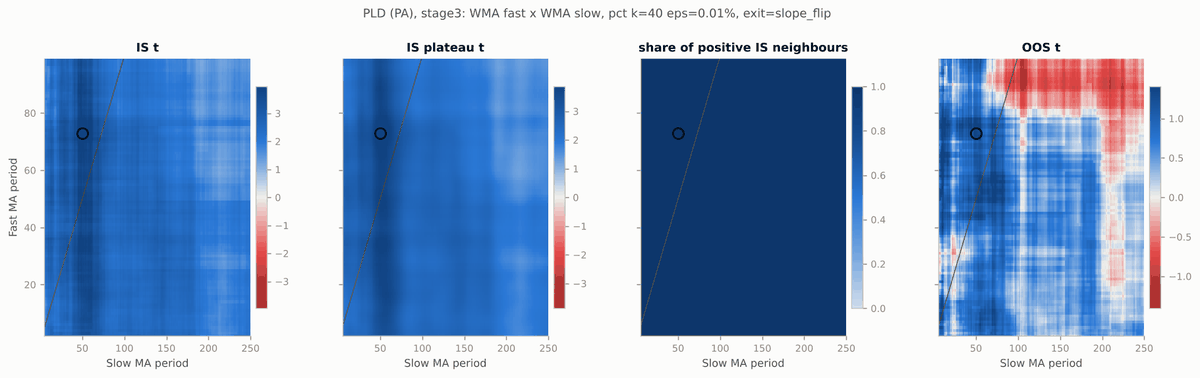

In [18]:
show("heatmap_stage3_pld.png")

## 5.8 Walk-forward: ежегодный переотбор — самый сильный результат

Каждый год параметры заново выбираются по трём предыдущим годам среди всех 3,47 млн конфигураций и торгуются
следующий год. Совокупный результат положителен на всех 6 рынках с длинной историей, после поправки Холма значимы
NG и PLT.

In [19]:
wf = table("walk_forward_summary.csv")
wf1 = wf[(wf["stage"] == "stage1") & (wf["scope"] == "all")].set_index("ticker").loc[INF[:-1]]
pd.DataFrame({"тестовых лет": wf1["test_years"], "лет в плюсе": wf1["positive_years"],
              "PnL, $ на контракт": wf1["test_pnl"].round().astype(int), "t": wf1["pooled_t"], "p": wf1["pooled_p"],
              "p (Холм)": holm(wf1["pooled_p"])}).rename(index=NAMES).rename_axis("инструмент")

,тестовых лет,лет в плюсе,"PnL, $ на контракт",t,p,p (Холм)
инструмент,,,,,,
NG,4,4,874,2.56,0.01,0.03
BR (Brent),13,9,881,1.15,0.12,0.16
GOLD (GC),13,6,1888,1.40,0.08,0.16
SILV (SI),13,9,862,2.11,0.02,0.06
PLT (PL),13,12,2935,2.60,0.00,0.03
PLD (PA),13,10,3019,2.16,0.02,0.06


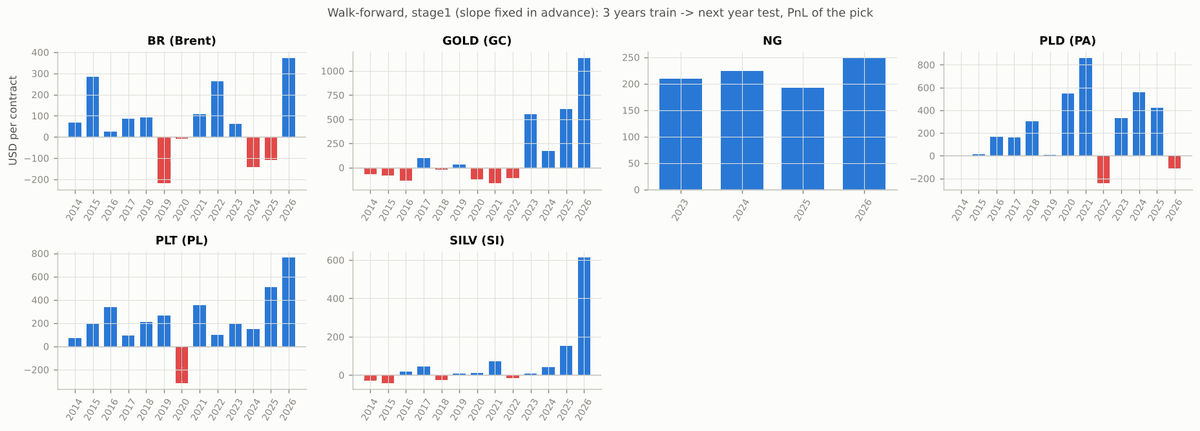

In [20]:
show("walk_forward_stage1.png")

## 5.9 Польза отбора и вероятность переобучения

* В среднем отобранная конфигурация оказывается на **65-м перцентиле** всех конфигураций тестового года
  (68 лет, z = 4,2). Отбор слабо, но надёжно лучше случайного выбора. Однако на NG, BR, PLT и PLD положительна
  и медианная конфигурация, так что заметная часть прибыли — общий трендовый дрейф.
* **PBO** (доля разбиений, где лучшая конфигурация одной половины истории хуже медианы на другой): на BR и PLT
  ≈ 0,5, то есть отбор переобучен; на PLD, SILV, GOLD и NG — 0,07–0,35.

In [21]:
(table("pbo.csv").pivot(index="ticker", columns="stage", values="pbo").loc[INF[:-1]].rename(index=NAMES)
 .rename(columns={"stage1": "PBO, этап 1", "stage3": "PBO, этап 3"}).rename_axis("инструмент", axis=0)
 .rename_axis(None, axis=1))

,"PBO, этап 1","PBO, этап 3"
инструмент,,
NG,0.20,0.35
BR (Brent),0.57,0.53
GOLD (GC),0.23,0.24
SILV (SI),0.16,0.13
PLT (PL),0.45,0.50
PLD (PA),0.27,0.07


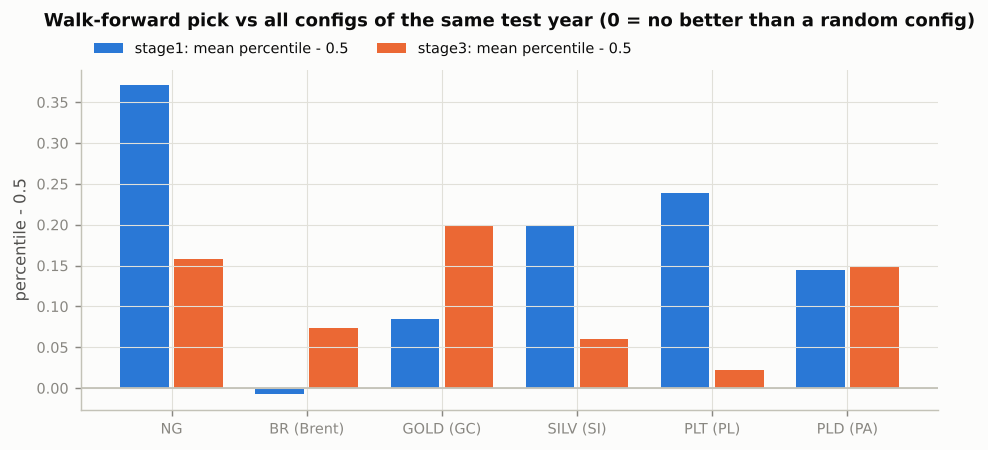

In [22]:
show("selection_skill.png", width=1000)

## 5.10 Межрыночная проверка

Одни и те же правила на всех рынках (этап 1). Строка — рынок, где выбрана лучшая по IS конфигурация, столбец —
рынок, где её проверили на OOS. Результат задаёт столбец, то есть режим проверяемого рынка: на золоте положителен
почти любой перенос. Ни одна конфигурация, отобранная честно (только по IS), не прибыльна на OOS на всех рынках:
лучшие дают плюс на 3–6 рынках из 7.

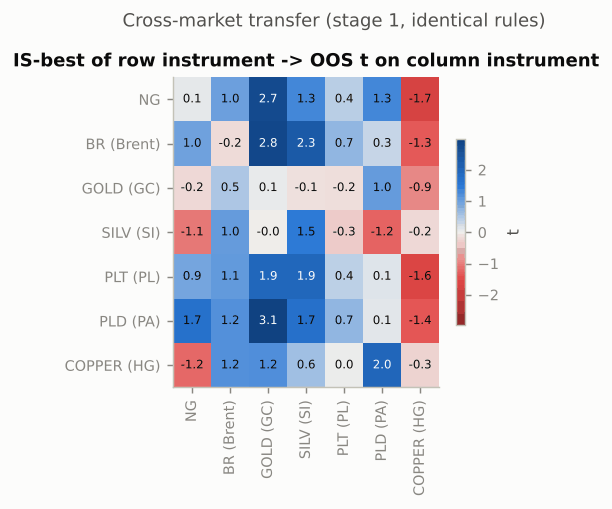

In [23]:
show("cross_market_transfer.png", width=900)

## 5.11 Экономика сделки: преимущество хрупкое

Средняя OOS-сделка финалистов NG, BR и SILV — 0,5–1,8 минимального шага цены. Спред и комиссия обычно стоят 1–2
тика на круг, и они съедят большую часть такой сделки или всю её. Комиссии и проскальзывание по ТЗ не
учитывались. У GOLD, PLT и PLD средняя сделка 16–137 тиков, но у неликвидных PLT и PLD выше и спред, и
проскальзывание.

In [24]:
pd.DataFrame({"OOS сделок": f["oos_trades"].astype(int), "средняя OOS-сделка, $": f["oos_avg_trade"],
              "в тиках": f["oos_avg_trade_ticks"], "средняя длительность OOS, ч": f["oos_avg_hours"],
              "MC: вероятность убытка на OOS": f["mc_oos_p_loss"]}).rename(index=NAMES).rename_axis("инструмент")

,OOS сделок,"средняя OOS-сделка, $",в тиках,"средняя длительность OOS, ч",MC: вероятность убытка на OOS
инструмент,,,,,
NG,911,0.17,1.71,13.05,0.30
BR (Brent),785,0.05,0.54,34.44,0.47
GOLD (GC),480,2.82,28.24,55.18,0.14
SILV (SI),1389,0.18,1.85,11.28,0.24
PLT (PL),588,1.64,16.41,30.85,0.18
PLD (PA),690,1.37,136.62,10.89,0.08
COPPER (HG),16,0.30,30.44,195.56,0.35


## 6. Итог: что получилось

| Вопрос | Ответ |
|---|---|
| Есть ли устойчиво прибыльные параметры? | **Нет.** После поправок на 9 млн проверок ни одна конфигурация не значима на OOS |
| Что важнее всего для результата? | **Режим рынка.** Знак результата меняется сразу у всей сетки |
| Какой выход лучше? | **Смена наклона Slow MA** — на 7 из 7 рынков на IS и на 6 из 7 на OOS |
| Какой горизонт наклона? | **k = 40–80 баров** (3–7 часов); порог ε и метод (% или ATR) почти не важны |
| Какие средние? | Различия второго порядка; медленная EMA, SSMA или WMA немного лучше |
| Fast ≥ Slow? | Не хуже стандартных пар |
| Работает ли регулярный переотбор? | **Да, слабо:** плюс на 6 из 6 рынков, значимо на NG и PLT; отбор на 65-м перцентиле |
| Можно ли торговать? | **Пока нет:** средняя сделка 0,5–1,8 тика на NG, BR, SILV, издержки не учтены |

**Рекомендации и следующие шаги**

1. Повторить лучшие правила (выход B, k = 40–80, walk-forward переотбор) **с комиссией MOEX и спредом**.
2. Проверить на 2026–2027 годах как на новой независимой выборке, без переподбора.
3. Проверить старшие таймфреймы (15m–60m): сделки там длиннее, и средняя сделка в тиках, вероятно, больше.
   Оценить ёмкость по объёмам.
4. Рассматривать трендовую экспозицию как режимный фактор портфеля, а не искать «правильные» периоды средних.

## 6. Где всё лежит

| Что | Где |
|---|---|
| Эта презентация | `notebooks/07_project_presentation.ipynb`, слайды — `07_project_presentation.slides.html` |
| Все сделки лучших конфигураций по порядку (16 349 сделок) | `notebooks/08_trade_ledger.ipynb`, `research/ma_cross_slope_5m/tables/trade_ledger.xlsx` |
| Подробный разбор и исследователь любой конфигурации (VectorBT) | `notebooks/06_ma_slope_research.ipynb` |
| Полный отчёт с методологией и ограничениями | `research/ma_cross_slope_5m/README.md` |
| Таблицы: рейтинг, финалисты, сделки, walk-forward, PBO… | `research/ma_cross_slope_5m/tables/` |
| Рисунки (40 PNG) | `research/ma_cross_slope_5m/figures/` |
| Все конфигурации всех этапов (parquet, ~1 ГБ) | `research/ma_cross_slope_5m/grid/` |
| Котировки AlgoPack (1m, 5m, 60m) и коэффициенты склейки | `data/raw/moex_algopack/` |
| Загрузчик котировок и склейка | `scripts/download_moex_algopack.py`, `src/data/moex_algopack_loader.py` |
| Код исследования | `src/ma_slope/`, `scripts/ma_slope_research.py` |

**Воспроизведение.** Каждый этап запускается одной командой (раздел 7 отчёта). Этапы возобновляемые. Сырые сетки
(≈ 17 ГБ) в git не входят из-за лимита GitHub на размер файла, но всё, что из них следует, лежит в репозитории.
Обновить котировки: `MOEX_ALGOPACK_TOKEN=... python scripts/download_moex_algopack.py --from 2026-01-01 ...`.